In [382]:
import pandas as pd

# Massachusetts Cannabis Control Commission Public Data URL
URL_MA_CANNABIS = "https://masscannabiscontrol.com/wp-content/uploads/2023/11/Marijuana_Establishment_Facility_Sales_and_Statistics.csv"

try:
    print("Attempting to load data from state portal...")

    df_sales = pd.read_csv(
        URL_MA_CANNABIS,
        storage_options={
            "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"
        },
    )
    print("Dataset loaded successfully!")

except Exception as e:
    print(f"Direct web fetch failed with error: {e}")
    print("\nFallback: Loading local file or downloading manually...")

    import numpy as np

    dates = pd.date_range(start="2021-01-01", end="2024-12-31", freq="D")
    base_sales = np.linspace(100000, 300000, len(dates))  # Growth trend
    seasonality = np.sin(np.linspace(0, 50 * np.pi, len(dates))) * 20000

    df_sales = pd.DataFrame(
        {
            "Sale Date": dates,
            "Gross Sales": base_sales
            + seasonality
            + np.random.normal(0, 5000, len(dates)),
            "Product Category": np.random.choice(
                ["Flower", "Edibles", "Concentrates"], len(dates)
            ),
        }
    )
    print("Fallback daily sales DataFrame created successfully!")

print(f"\nDataFrame Shape: {df_sales.shape}")
print(df_sales.head())

Attempting to load data from state portal...
Direct web fetch failed with error: HTTP Error 404: Not Found

Fallback: Loading local file or downloading manually...
Fallback daily sales DataFrame created successfully!

DataFrame Shape: (1461, 3)
   Sale Date    Gross Sales Product Category
0 2021-01-01   98030.571636     Concentrates
1 2021-01-02  100223.436127     Concentrates
2 2021-01-03  109618.911843          Edibles
3 2021-01-04   99185.107495           Flower
4 2021-01-05  110581.314372           Flower


In [383]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

from catboost import CatBoostRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score)
from xgboost import XGBRegressor
from sklearn.ensemble import GradientBoostingRegressor

In [384]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.model_selection import train_test_split

In [385]:
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge

In [386]:
df_sales.head(10)

,Sale Date,Gross Sales,Product Category
0,2021-01-01,98030.571636,Concentrates
1,2021-01-02,100223.436127,Concentrates
2,2021-01-03,109618.911843,Edibles
3,2021-01-04,99185.107495,Flower
4,2021-01-05,110581.314372,Flower
5,2021-01-06,111989.744192,Concentrates
6,2021-01-07,104982.538066,Concentrates
7,2021-01-08,109821.308723,Flower
8,2021-01-09,117203.687685,Concentrates
9,2021-01-10,107428.571057,Concentrates


In [387]:
df_sales.shape

(1461, 3)

In [388]:
df_sales.isnull().sum()

Sale Date           0
Gross Sales         0
Product Category    0
dtype: int64

In [389]:
df_sales.duplicated().sum()

np.int64(0)

In [390]:
df_sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1461 entries, 0 to 1460
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Sale Date         1461 non-null   datetime64[ns]
 1   Gross Sales       1461 non-null   float64       
 2   Product Category  1461 non-null   object        
dtypes: datetime64[ns](1), float64(1), object(1)
memory usage: 34.4+ KB


In [391]:
print(df_sales['Sale Date'].min())
print(df_sales['Sale Date'].max())

2021-01-01 00:00:00
2024-12-31 00:00:00


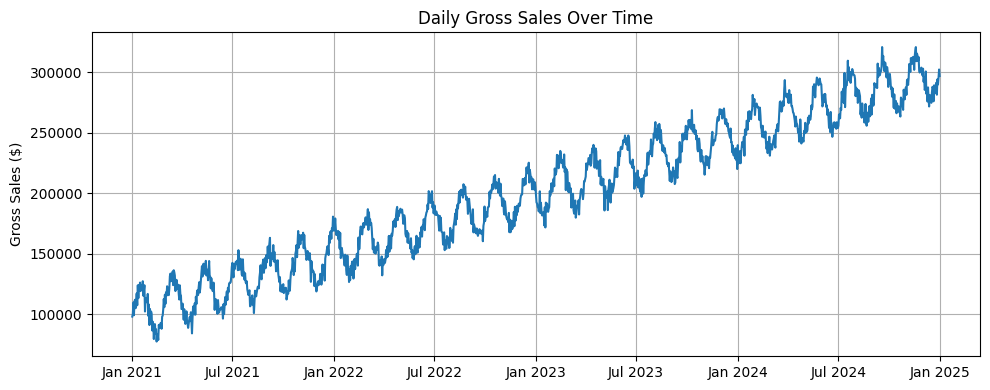

In [392]:
daily_sales = df_sales.groupby("Sale Date")["Gross Sales"].sum()

plt.figure(figsize=(10, 4))
plt.plot(daily_sales)

plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

plt.title("Daily Gross Sales Over Time")
plt.ylabel("Gross Sales ($)")
plt.grid(True)
plt.tight_layout()
plt.show()

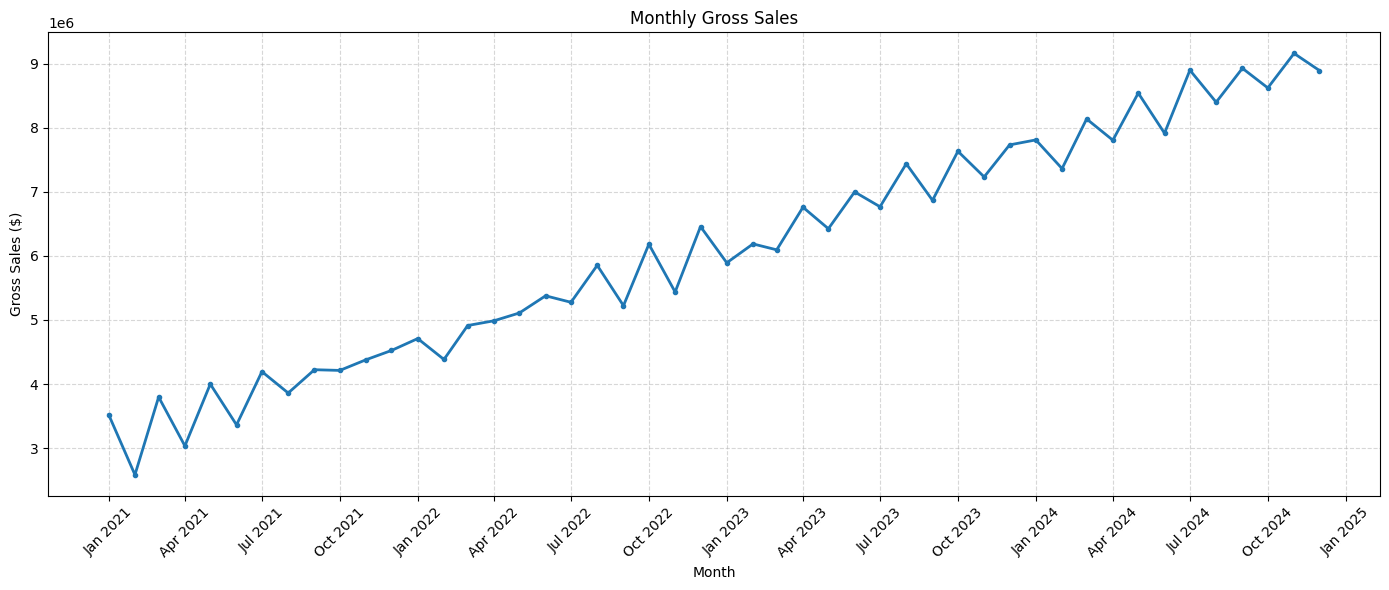

In [393]:
monthly_sales = df_sales.groupby(df_sales["Sale Date"].dt.to_period("M"))["Gross Sales"].sum()
monthly_sales.index = monthly_sales.index.to_timestamp() 

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(monthly_sales.index, monthly_sales.values, linewidth=2, marker='o', markersize=3)

ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

ax.set_title('Monthly Gross Sales')
ax.set_xlabel('Month')
ax.set_ylabel('Gross Sales ($)')
plt.xticks(rotation=45)
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [434]:
monthly_sales

Sale Date
2021-01-01    3.521671e+06
2021-02-01    2.584270e+06
2021-03-01    3.797319e+06
2021-04-01    3.034349e+06
2021-05-01    3.999134e+06
2021-06-01    3.362257e+06
2021-07-01    4.193213e+06
2021-08-01    3.859952e+06
2021-09-01    4.223150e+06
2021-10-01    4.212349e+06
2021-11-01    4.379166e+06
2021-12-01    4.523418e+06
2022-01-01    4.709021e+06
2022-02-01    4.383056e+06
2022-03-01    4.912653e+06
2022-04-01    4.986581e+06
2022-05-01    5.108271e+06
2022-06-01    5.376346e+06
2022-07-01    5.275233e+06
2022-08-01    5.851751e+06
2022-09-01    5.222385e+06
2022-10-01    6.181084e+06
2022-11-01    5.436092e+06
2022-12-01    6.456392e+06
2023-01-01    5.891608e+06
2023-02-01    6.185911e+06
2023-03-01    6.093706e+06
2023-04-01    6.758156e+06
2023-05-01    6.423001e+06
2023-06-01    6.997035e+06
2023-07-01    6.765893e+06
2023-08-01    7.436302e+06
2023-09-01    6.866292e+06
2023-10-01    7.630998e+06
2023-11-01    7.231285e+06
2023-12-01    7.730527e+06
2024-01-01    7.80

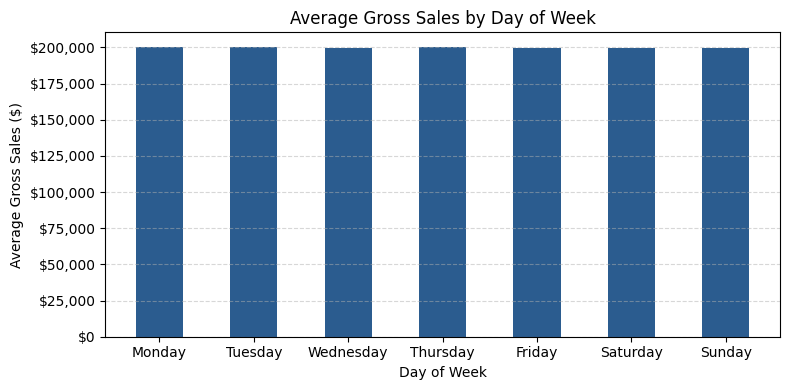

In [394]:
df_sales["Day of Week"] = df_sales["Sale Date"].dt.day_name()

dow_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday",
]
dow_sales = (
    df_sales.groupby("Day of Week")["Gross Sales"].mean().reindex(dow_order)
)
plt.figure(figsize=(8, 4))
plt.bar(dow_sales.index, dow_sales.values, color="#2b5c8f", width=0.5)

plt.gca().yaxis.set_major_formatter("${x:,.0f}")
plt.title("Average Gross Sales by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Gross Sales ($)")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

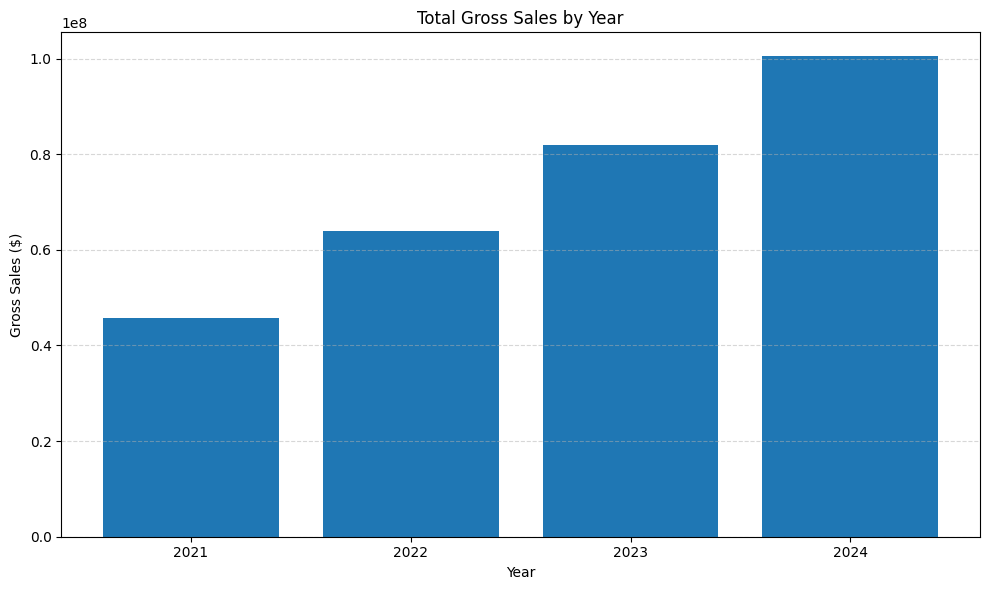

In [395]:
yearly_sales = df_sales.groupby(df_sales["Sale Date"].dt.year)["Gross Sales"].sum()

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(yearly_sales.index.astype(str), yearly_sales.values)

ax.set_title('Total Gross Sales by Year')
ax.set_xlabel('Year')
ax.set_ylabel('Gross Sales ($)')
ax.grid(True, axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [433]:
yearly_sales

Sale Date
2021    4.569025e+07
2022    6.389887e+07
2023    8.201072e+07
2024    1.004502e+08
Name: Gross Sales, dtype: float64

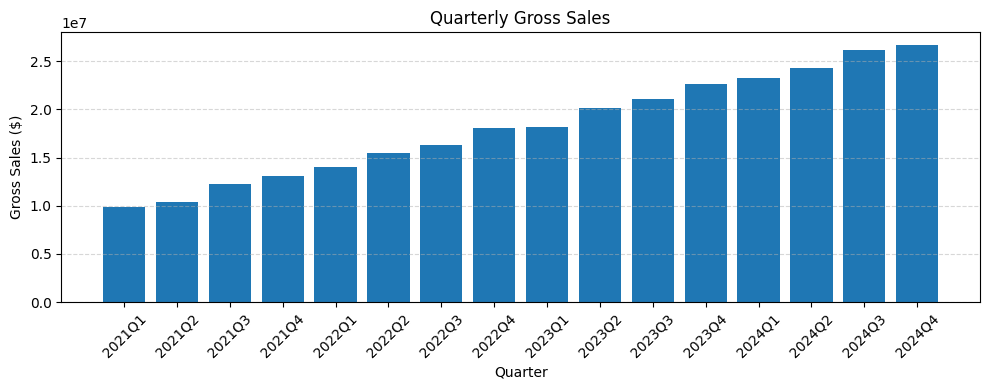

In [396]:
quarterly_sales = df_sales.groupby(
    df_sales["Sale Date"].dt.to_period("Q")
)["Gross Sales"].sum()

plt.figure(figsize=(10, 4))
plt.bar(quarterly_sales.index.astype(str), quarterly_sales.values)
plt.title("Quarterly Gross Sales")
plt.xlabel("Quarter")
plt.ylabel("Gross Sales ($)")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [432]:
quarterly_sales

Sale Date
2021Q1    9.903260e+06
2021Q2    1.039574e+07
2021Q3    1.227632e+07
2021Q4    1.311493e+07
2022Q1    1.400473e+07
2022Q2    1.547120e+07
2022Q3    1.634937e+07
2022Q4    1.807357e+07
2023Q1    1.817122e+07
2023Q2    2.017819e+07
2023Q3    2.106849e+07
2023Q4    2.259281e+07
2024Q1    2.330511e+07
2024Q2    2.425650e+07
2024Q3    2.621944e+07
2024Q4    2.666913e+07
Freq: Q-DEC, Name: Gross Sales, dtype: float64

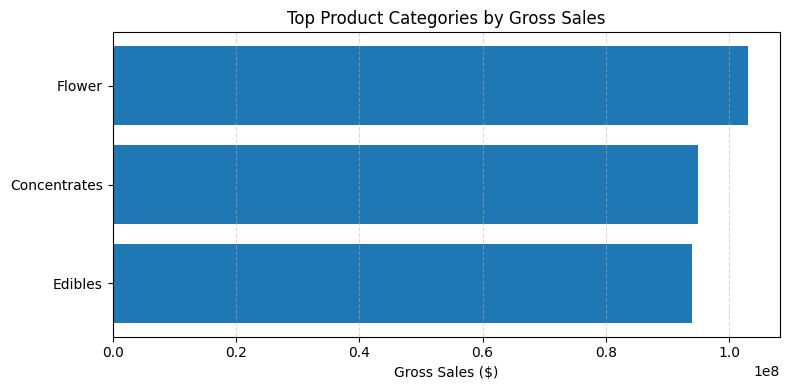

In [397]:
product_cat = (
    df_sales.groupby("Product Category")["Gross Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)
plt.figure(figsize=(8, 4))
plt.barh(product_cat.index[::-1], product_cat.values[::-1])
plt.title("Top Product Categories by Gross Sales")
plt.xlabel("Gross Sales ($)")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [436]:
product_cat

Product Category
Flower          1.030860e+08
Concentrates    9.498650e+07
Edibles         9.397755e+07
Name: Gross Sales, dtype: float64

In [398]:
#Make a copy of the dataset
daily_sales = df_sales.copy()

In [399]:
daily_sales.head(3)

,Sale Date,Gross Sales,Product Category,Day of Week
0,2021-01-01,98030.571636,Concentrates,Friday
1,2021-01-02,100223.436127,Concentrates,Saturday
2,2021-01-03,109618.911843,Edibles,Sunday


In [400]:
daily_sales["Month"] = daily_sales["Sale Date"].dt.month
daily_sales["Day"] = daily_sales["Sale Date"].dt.day
daily_sales["Year"] = daily_sales["Sale Date"].dt.year

# Flag Q4 High-Seasonality Months (Oct, Nov, Dec)
daily_sales["is_q4"] = daily_sales["Month"].isin([10, 11, 12]).astype(int)

# Flag Paydays / End-of-Month Spikes
daily_sales["is_month_start"] = (daily_sales["Day"] <= 3).astype(int)
daily_sales["is_month_end"] = (daily_sales["Day"] >= 28).astype(int)

In [401]:
# Create a DayofWeek column and Weekend column
daily_sales['DayOfWeek'] = daily_sales['Sale Date'].dt.dayofweek
daily_sales['IsWeekend'] = (daily_sales['DayOfWeek'] >= 5).astype(int)

In [402]:
daily_sales["time_step"] = range(len(daily_sales))

In [403]:
daily_sales = daily_sales.drop(columns= ['Product Category'])

In [404]:
daily_sales.head(5)

,Sale Date,Gross Sales,Day of Week,Month,Day,Year,is_q4,is_month_start,is_month_end,DayOfWeek,IsWeekend,time_step
0,2021-01-01,98030.571636,Friday,1,1,2021,0,1,0,4,0,0
1,2021-01-02,100223.436127,Saturday,1,2,2021,0,1,0,5,1,1
2,2021-01-03,109618.911843,Sunday,1,3,2021,0,1,0,6,1,2
3,2021-01-04,99185.107495,Monday,1,4,2021,0,0,0,0,0,3
4,2021-01-05,110581.314372,Tuesday,1,5,2021,0,0,0,1,0,4


In [405]:
daily_sales['lag_1'] = daily_sales['Gross Sales'].shift(1)    
daily_sales['lag_7'] = daily_sales['Gross Sales'].shift(7)    
daily_sales['lag_30'] = daily_sales['Gross Sales'].shift(30) 

In [406]:
# Creating Rolling features
# Rolling features on Log Target (shifted by 1 to prevent data leakage)
daily_sales['rolling_mean_7'] = (daily_sales['Gross Sales'].shift(1).rolling(7).mean())
daily_sales['rolling_mean_30'] = (daily_sales['Gross Sales'].shift(1).rolling(30).mean())

In [407]:
daily_sales = daily_sales.dropna().reset_index(drop=True)

In [408]:
# Check head
daily_sales.head(5)

,Sale Date,Gross Sales,Day of Week,Month,Day,Year,is_q4,is_month_start,is_month_end,DayOfWeek,IsWeekend,time_step,lag_1,lag_7,lag_30,rolling_mean_7,rolling_mean_30
0,2021-01-31,108031.512143,Sunday,1,31,2021,0,0,1,6,1,30,98669.202535,102247.935587,98030.571636,109132.221116,113787.981762
1,2021-02-01,91046.533301,Monday,2,1,2021,0,1,0,0,0,31,108031.512143,111006.943840,100223.436127,109958.446338,114121.346445
2,2021-02-02,104375.873871,Tuesday,2,2,2021,0,1,0,1,0,32,91046.533301,113513.616837,109618.911843,107106.959118,113815.449685
3,2021-02-03,94869.666701,Wednesday,2,3,2021,0,1,0,2,0,33,104375.873871,111908.578561,99185.107495,105801.567266,113640.681752
4,2021-02-04,102244.151039,Thursday,2,4,2021,0,0,0,3,0,34,94869.666701,109784.064044,110581.314372,103367.437001,113496.833726


In [409]:
daily_sales.isnull().sum()

Sale Date          0
Gross Sales        0
Day of Week        0
Month              0
Day                0
Year               0
is_q4              0
is_month_start     0
is_month_end       0
DayOfWeek          0
IsWeekend          0
time_step          0
lag_1              0
lag_7              0
lag_30             0
rolling_mean_7     0
rolling_mean_30    0
dtype: int64

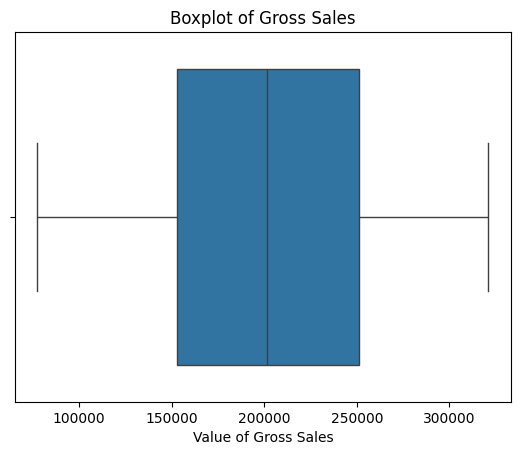

In [410]:
import seaborn as sns
sns.boxplot(x=daily_sales['Gross Sales'])
plt.title('Boxplot of Gross Sales')
plt.xlabel('Value of Gross Sales')
plt.show()

In [411]:
daily_sales.describe()

,Sale Date,Gross Sales,Month,Day,Year,is_q4,is_month_start,is_month_end,DayOfWeek,IsWeekend,time_step,lag_1,lag_7,lag_30,rolling_mean_7,rolling_mean_30
count,1431,1431.000000,1431.000000,1431.000000,1431.000000,1431.000000,1431.000000,1431.000000,1431.000000,1431.000000,1431.00000,1431.000000,1431.000000,1431.000000,1431.000000,1431.000000
mean,2023-01-15 23:59:59.999999744,201702.570124,6.638714,15.734451,2022.532495,0.257163,0.098532,0.113208,2.998602,0.285814,745.00000,201563.920857,200802.074282,198086.771950,201181.770774,199837.747786
min,2021-01-31 00:00:00,77396.124888,1.000000,1.000000,2021.000000,0.000000,0.000000,0.000000,0.000000,0.000000,30.00000,77396.124888,77396.124888,77396.124888,83612.728015,93032.358295
25%,2022-01-23 12:00:00,152847.277901,4.000000,8.000000,2022.000000,0.000000,0.000000,0.000000,1.000000,0.000000,387.50000,152519.483542,151002.375414,148615.817063,152243.700408,151148.092440
50%,2023-01-16 00:00:00,201691.585418,7.000000,16.000000,2023.000000,0.000000,0.000000,0.000000,3.000000,0.000000,745.00000,201543.383760,201005.068289,198319.887710,200896.087079,199206.617922
75%,2024-01-08 12:00:00,251232.321893,10.000000,23.000000,2024.000000,1.000000,0.000000,0.000000,5.000000,1.000000,1102.50000,251146.079307,250412.624861,246804.900765,250376.282253,249105.118551
max,2024-12-31 00:00:00,321025.321270,12.000000,31.000000,2024.000000,1.000000,1.000000,1.000000,6.000000,1.000000,1460.00000,321025.321270,321025.321270,321025.321270,314501.663954,306014.155912
std,NaN,58712.371177,3.390878,8.806112,1.108845,0.437223,0.298137,0.316957,2.002446,0.451959,413.23843,58721.257116,58713.500452,58707.270833,58439.898218,57419.375667


In [412]:
df_corr= daily_sales.corr(numeric_only=True).abs()
df_corr

,Gross Sales,Month,Day,Year,is_q4,is_month_start,is_month_end,DayOfWeek,IsWeekend,time_step,lag_1,lag_7,lag_30,rolling_mean_7,rolling_mean_30
Gross Sales,1.000000,0.204045,0.027092,0.933832,0.169549,0.013752,0.016507,0.000918,0.000970,0.966859,0.992172,0.976965,0.877410,0.990569,0.951848
Month,0.204045,1.000000,0.010017,0.048487,0.757027,0.002116,0.017911,0.004663,0.000107,0.202562,0.204149,0.201538,0.190762,0.203367,0.200591
Day,0.027092,0.010017,1.000000,0.000669,0.006851,0.515815,0.551446,0.002081,0.005378,0.024425,0.027438,0.023129,0.027589,0.025878,0.021202
Year,0.933832,0.048487,0.000669,1.000000,0.017249,0.000173,0.001464,0.001239,0.000293,0.968064,0.933807,0.934555,0.937101,0.938491,0.956593
is_q4,0.169549,0.757027,0.006851,0.017249,1.000000,0.001395,0.011806,0.003606,0.002903,0.172699,0.169915,0.167521,0.165468,0.169118,0.170326
is_month_start,0.013752,0.002116,0.515815,0.000173,0.001395,1.000000,0.118125,0.003283,0.006746,0.011681,0.013476,0.008602,0.018084,0.010278,0.010210
is_month_end,0.016507,0.017911,0.551446,0.001464,0.011806,0.118125,1.000000,0.001351,0.003408,0.017587,0.018189,0.018641,0.015760,0.018845,0.016199
DayOfWeek,0.000918,0.004663,0.002081,0.001239,0.003606,0.003283,0.001351,1.000000,0.790901,0.000004,0.001044,0.001041,0.001490,0.000078,0.000075
IsWeekend,0.000970,0.000107,0.005378,0.000293,0.002903,0.006746,0.003408,0.790901,1.000000,0.000378,0.000546,0.001400,0.002322,0.000272,0.000355
time_step,0.966859,0.202562,0.024425,0.968064,0.172699,0.011681,0.017587,0.000004,0.000378,1.000000,0.966868,0.966861,0.966786,0.971232,0.988196


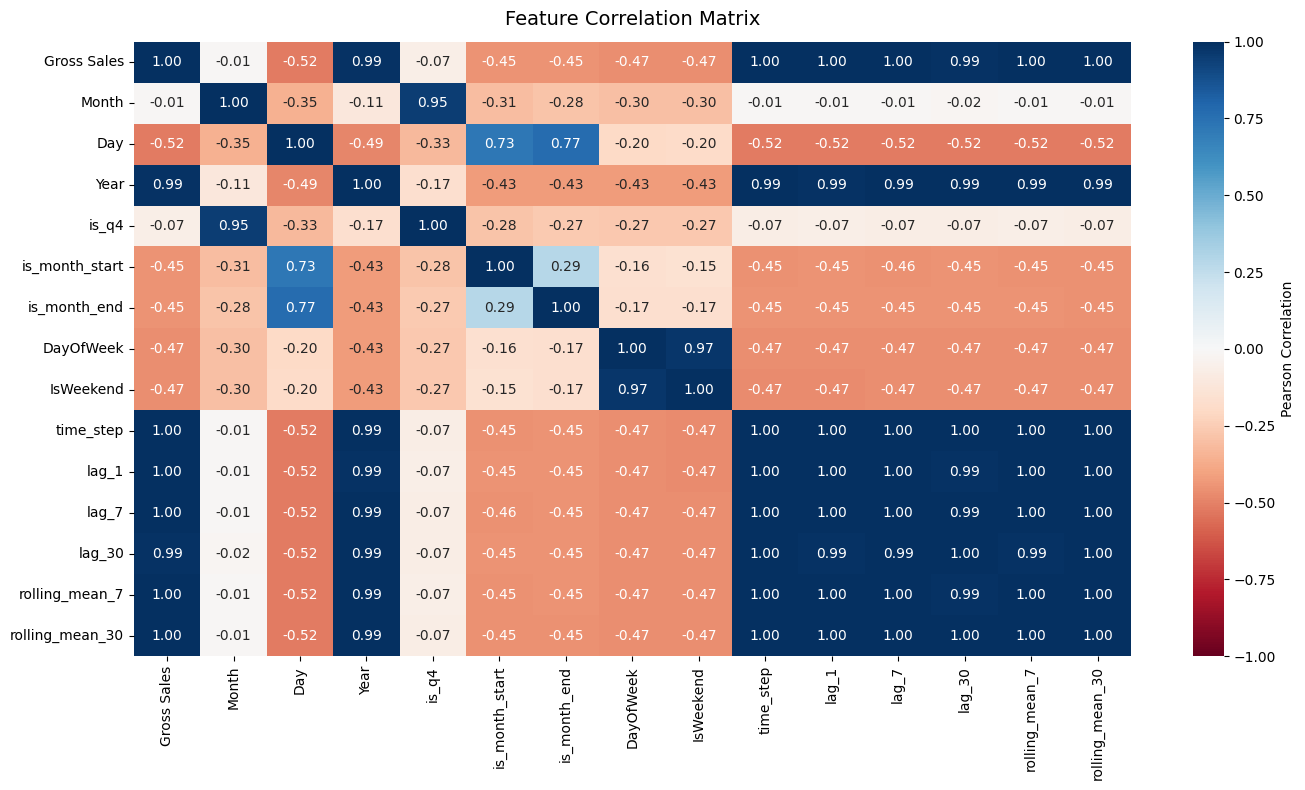

In [413]:
plt.figure(figsize=(14, 8))

sns.heatmap(
    df_corr.corr(),
    annot=True,
    fmt=".2f",  
    cmap="RdBu",
    vmin=-1,
    vmax=1,
    cbar_kws={"label": "Pearson Correlation"},
)

plt.title("Feature Correlation Matrix", fontsize=14, pad=12)
plt.tight_layout()
plt.show()

In [414]:
daily_sales.columns

Index(['Sale Date', 'Gross Sales', 'Day of Week', 'Month', 'Day', 'Year',
       'is_q4', 'is_month_start', 'is_month_end', 'DayOfWeek', 'IsWeekend',
       'time_step', 'lag_1', 'lag_7', 'lag_30', 'rolling_mean_7',
       'rolling_mean_30'],
      dtype='object')

In [415]:
feature_cols = ['Month', 'Day', 'Year', 'is_q4',
       'is_month_start', 'is_month_end', 'DayOfWeek', 'IsWeekend', 'time_step',
       'lag_1', 'lag_7', 'lag_30', 'rolling_mean_7',
       'rolling_mean_30']

In [416]:
X = daily_sales[feature_cols]
y = daily_sales['Gross Sales']

In [417]:
y

0       108031.512143
1        91046.533301
2       104375.873871
3        94869.666701
4       102244.151039
            ...      
1426    294348.203396
1427    290071.004411
1428    295454.096457
1429    302465.104700
1430    297076.304510
Name: Gross Sales, Length: 1431, dtype: float64

In [418]:
X

,Month,Day,Year,is_q4,is_month_start,is_month_end,DayOfWeek,IsWeekend,time_step,lag_1,lag_7,lag_30,rolling_mean_7,rolling_mean_30
0,1,31,2021,0,0,1,6,1,30,98669.202535,102247.935587,98030.571636,109132.221116,113787.981762
1,2,1,2021,0,1,0,0,0,31,108031.512143,111006.943840,100223.436127,109958.446338,114121.346445
2,2,2,2021,0,1,0,1,0,32,91046.533301,113513.616837,109618.911843,107106.959118,113815.449685
3,2,3,2021,0,1,0,2,0,33,104375.873871,111908.578561,99185.107495,105801.567266,113640.681752
4,2,4,2021,0,0,0,3,0,34,94869.666701,109784.064044,110581.314372,103367.437001,113496.833726
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1426,12,27,2024,1,0,0,4,0,1456,281615.800275,276138.017689,301951.150206,284233.786579,287209.810401
1427,12,28,2024,1,0,1,5,1,1457,294348.203396,289380.539302,304016.721161,286835.241680,286956.378841
1428,12,29,2024,1,0,1,6,1,1458,290071.004411,283018.433981,301171.660353,286933.879553,286491.521616
1429,12,30,2024,1,0,1,0,0,1459,295454.096457,284757.504852,297602.692622,288710.402763,286300.936153


In [419]:
# Find the index position for the 80% 
split_idx = int(len(daily_sales) * 0.8)

In [420]:
#Split the X and y by 0-80 & 80-100

X_train = X.iloc[:split_idx]
X_test = X.iloc[split_idx:]

y_train = y.iloc[:split_idx]
y_test = y.iloc[split_idx:]

In [421]:
# Initialize 5-fold TimeSeriesSplit
tscv = TimeSeriesSplit(n_splits=5, test_size=30)

In [422]:
print(f"Train: {X_train.shape[0]} rows | Test: {X_test.shape[0]} rows")
print(f"Train period: {daily_sales['Sale Date'].iloc[0]} to {daily_sales['Sale Date'].iloc[split_idx-1]}")
print(f"Test period:  {daily_sales['Sale Date'].iloc[split_idx]} to {daily_sales['Sale Date'].iloc[-1]}")

Train: 1144 rows | Test: 287 rows
Train period: 2021-01-31 00:00:00 to 2024-03-19 00:00:00
Test period:  2024-03-20 00:00:00 to 2024-12-31 00:00:00


In [423]:
# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

# Random Forest
rf = RandomForestRegressor(n_estimators=200, max_depth=10, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

# CatBoost
cb = CatBoostRegressor(
    iterations=200, depth=6, learning_rate=0.05, verbose=0, random_seed=42
)
cb.fit(X_train, y_train)
cb_pred = cb.predict(X_test)

# 4. XGBoost
xgb = XGBRegressor(
    n_estimators=200, max_depth=6, learning_rate=0.05, random_state=42
)
xgb.fit(X_train, y_train)
xgb_pred = xgb.predict(X_test)

In [424]:
# Evaluation Function
def evaluate(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"{name:<20}: MAE={mae:,.0f}  RMSE={rmse:,.0f}  R2={r2:.3f}")


# Evaluate All Models
evaluate("Linear Regression", y_test, lr_pred)
evaluate("Random Forest", y_test, rf_pred)
evaluate("CatBoost", y_test, cb_pred)
evaluate("XGBoost", y_test, xgb_pred)

Linear Regression   : MAE=4,445  RMSE=5,616  R2=0.900
Random Forest       : MAE=16,190  RMSE=20,678  R2=-0.360
CatBoost            : MAE=18,480  RMSE=23,357  R2=-0.735
XGBoost             : MAE=20,212  RMSE=24,844  R2=-0.963


In [425]:
# Gradient Boosting
gb_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gb_model.fit(X_train, y_train)

gb_pred = gb_model.predict(X_test)

print("Gradient Boosting")
print(f"MAE: ${mean_absolute_error(y_test, gb_pred):,.0f}")
print(f"RMSE: ${mean_squared_error(y_test, gb_pred) ** 0.5:,.0f}")
print(f"R²: {r2_score(y_test, gb_pred):.3f}")

Gradient Boosting
MAE: $13,760
RMSE: $18,168
R²: -0.050


In [426]:
from sklearn.linear_model import Ridge
# Ridge
ridge_model = Ridge(alpha=1.0)

ridge_model.fit(X_train, y_train)

ridge_pred = ridge_model.predict(X_test)

print("Ridge Regression")
print(f"MAE: ${mean_absolute_error(y_test, ridge_pred):,.0f}")
print(f"RMSE: ${mean_squared_error(y_test, ridge_pred) ** 0.5:,.0f}")
print(f"R²: {r2_score(y_test, ridge_pred):.3f}")

Ridge Regression
MAE: $4,444
RMSE: $5,615
R²: 0.900


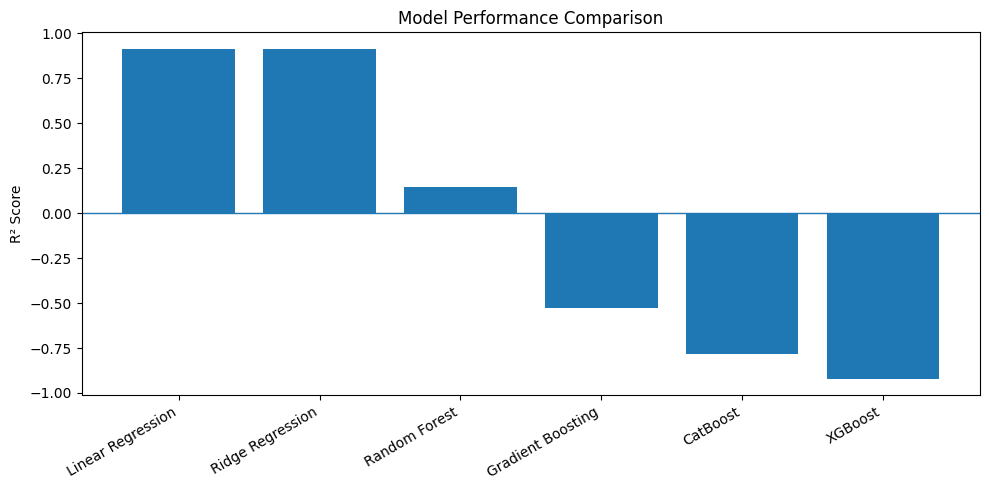

In [427]:
models = [
    'Linear Regression',
    'Ridge Regression',
    'Random Forest',
    'Gradient Boosting',
    'CatBoost',
    'XGBoost'
]

r2_scores = [
    0.914,
    0.914,
    0.146,
    -0.529,
    -0.781,
    -0.921
]

plt.figure(figsize=(10, 5))

plt.bar(models, r2_scores)

plt.axhline(0, linewidth=1)

plt.ylabel('R² Score')
plt.title('Model Performance Comparison')
plt.xticks(rotation=30, ha='right')

plt.tight_layout()
plt.show()

In [428]:
daily_sales[
    ['Gross Sales',
     'lag_1',
     'lag_7',
     'lag_30',
     'rolling_mean_7',
     'rolling_mean_30']
].corr()['Gross Sales'].sort_values(ascending=False)

Gross Sales        1.000000
lag_1              0.992172
rolling_mean_7     0.990569
lag_7              0.976965
rolling_mean_30    0.951848
lag_30             0.877410
Name: Gross Sales, dtype: float64

In [429]:
lr_model = LinearRegression()
ridge_model = Ridge(alpha=1.0)

lr_scores = cross_val_score(
    lr_model,
    X_train,
    y_train,
    cv=tscv,
    scoring='r2'
)

ridge_scores = cross_val_score(
    ridge_model,
    X_train,
    y_train,
    cv=tscv,
    scoring='r2'
)

print("Linear Regression R²:", lr_scores)
print("Mean:", lr_scores.mean())

print("\nRidge Regression R²:", ridge_scores)
print("Mean:", ridge_scores.mean())

Linear Regression R²: [0.56291036 0.73594483 0.70084712 0.69793794 0.8253114 ]
Mean: 0.70459033067231

Ridge Regression R²: [0.56321742 0.73518963 0.70101987 0.70002988 0.82524208]
Mean: 0.7049397765217472


In [430]:
comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': lr_pred
})

comparison['Error'] = (
    comparison['Actual'] - comparison['Predicted']
)

comparison.head(10)

,Actual,Predicted,Error
0,267601.470071,274154.711849,-6553.241778
1,268818.011583,275293.922036,-6475.910453
2,274052.381679,277959.106734,-3906.725054
3,276243.320442,279889.160113,-3645.839671
4,272585.230187,280088.677922,-7503.447735
5,286292.836572,279506.854738,6785.981834
6,293700.042017,279107.201137,14592.840880
7,283308.169634,281302.012664,2006.156970
8,282523.987696,281365.094682,1158.893014
9,279523.752437,283532.795265,-4009.042828


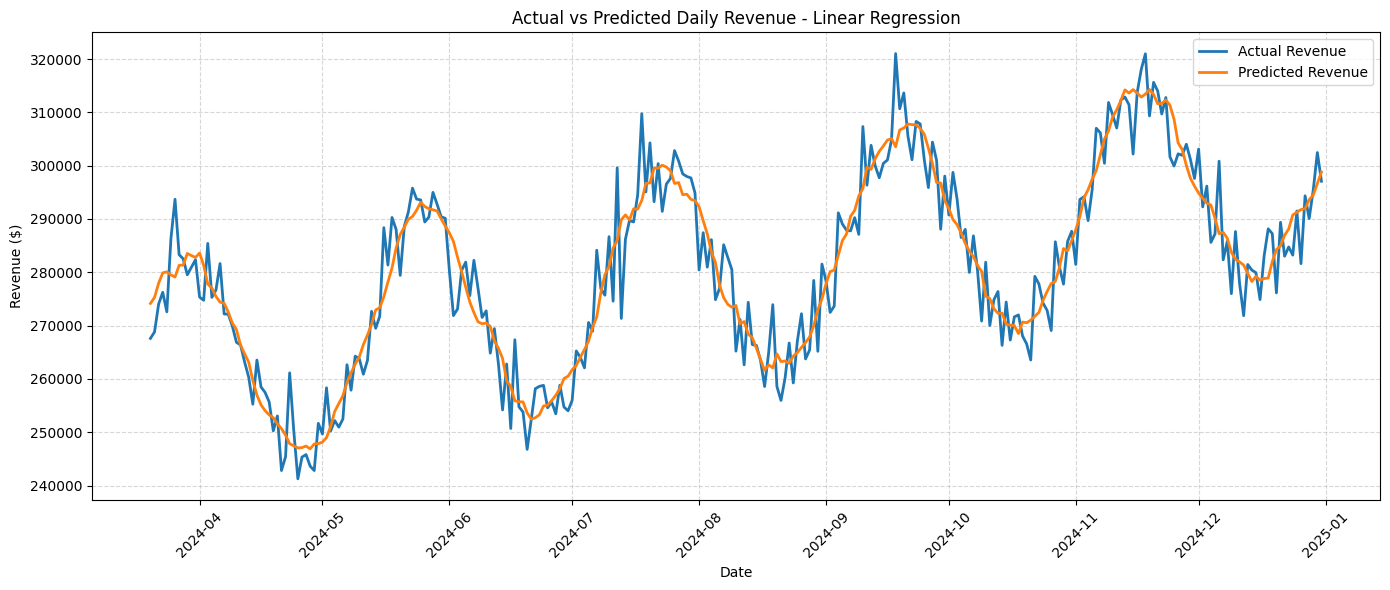

In [431]:
# Create Date from Year, Month and Day
dates = pd.to_datetime(
    daily_sales[['Year', 'Month', 'Day']]
)

comparison = pd.DataFrame({
    'Date': dates.iloc[split_idx:].values,
    'Actual Revenue': y_test.values,
    'Predicted Revenue': lr_pred
})

plt.figure(figsize=(14, 6))

plt.plot(
    comparison['Date'],
    comparison['Actual Revenue'],
    label='Actual Revenue',
    linewidth=2
)

plt.plot(
    comparison['Date'],
    comparison['Predicted Revenue'],
    label='Predicted Revenue',
    linewidth=2
)

plt.title('Actual vs Predicted Daily Revenue - Linear Regression')
plt.xlabel('Date')
plt.ylabel('Revenue ($)')
plt.legend()
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [437]:
df_sales.info()
df_sales.describe()
df_sales.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1461 entries, 0 to 1460
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Sale Date         1461 non-null   datetime64[ns]
 1   Gross Sales       1461 non-null   float64       
 2   Product Category  1461 non-null   object        
 3   Day of Week       1461 non-null   object        
dtypes: datetime64[ns](1), float64(1), object(2)
memory usage: 45.8+ KB


Sale Date           0
Gross Sales         0
Product Category    0
Day of Week         0
dtype: int64

In [438]:
df_sales.groupby("Product Category")["Gross Sales"].agg(
    ["sum", "mean", "min", "max"]
)

,sum,mean,min,max
Product Category,,,,
Concentrates,9.498650e+07,197477.127198,79476.958390,312785.258206
Edibles,9.397755e+07,199527.708478,78696.487985,321025.321270
Flower,1.030860e+08,202526.460562,77396.124888,320989.454430


In [439]:
monthly_sales.idxmax(), monthly_sales.max()
monthly_sales.idxmin(), monthly_sales.min()

(Timestamp('2021-02-01 00:00:00'), np.float64(2584270.03418153))

In [440]:
daily_sales[feature_cols + ["Gross Sales"]].corr()["Gross Sales"].sort_values(ascending=False)

Gross Sales        1.000000
lag_1              0.992172
rolling_mean_7     0.990569
lag_7              0.976965
time_step          0.966859
rolling_mean_30    0.951848
Year               0.933832
lag_30             0.877410
Month              0.204045
is_q4              0.169549
Day                0.027092
is_month_end       0.016507
DayOfWeek         -0.000918
IsWeekend         -0.000970
is_month_start    -0.013752
Name: Gross Sales, dtype: float64